In [ ]:
!pip install sentinelhub rasterio geopandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.3/242.3 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.3 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime, timedelta
from sentinelhub import (
    SHConfig, BBox, CRS, SentinelHubRequest, MimeType,
    DataCollection, bbox_to_dimensions, MosaickingOrder
)
from rasterio.transform import from_bounds
from google.colab import files

# === Sentinel Hub Config ===
config = SHConfig()
config.sh_client_id = ""
config.sh_client_secret = ""
config.download_timeout_seconds = 60


# === Region definitions ===
regions = {
    "Baramati": [74.8295, 18.1215, 74.8325, 18.1245],
    "Pune": [73.8567, 18.5204, 73.8667, 18.5304],
    "Nashik": [73.7898, 20.0059, 73.7998, 20.0159]
}


# === Seasonal date ranges ===
seasons = {
    "Monsoon": ("2023-07-01", "2023-09-30"),
    "PostMonsoon": ("2023-10-01", "2023-11-30"),
    "Winter": ("2023-12-01", "2024-02-28"),
    "Summer": ("2024-03-01", "2024-05-31")
}

# === Evalscript (7 bands) ===
evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["B02", "B03", "B04", "B05", "B08", "B11", "B12"],
    output: { bands: 7, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(sample) {
  return [
    sample.B02, sample.B03, sample.B04,
    sample.B05, sample.B08, sample.B11, sample.B12
  ];
}
"""

# === Data collection ===
all_data = []

for region_name, coords in regions.items():
    bbox = BBox(bbox=coords, crs=CRS.WGS84)
    size = bbox_to_dimensions(bbox, resolution=10)

    for season_name, (start, end) in seasons.items():
        print(f"\n📦 Fetching for {region_name} - {season_name}")
        try:
            request = SentinelHubRequest(
                evalscript=evalscript,
                input_data=[SentinelHubRequest.input_data(
                    data_collection=DataCollection.SENTINEL2_L2A,
                    time_interval=(start, end),
                    mosaicking_order=MosaickingOrder.MOST_RECENT
                )],
                responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
                bbox=bbox,
                size=size,
                config=config
            )

            images = request.get_data(save_data=False)
            if not images:
                print("⚠ No image returned.")
                continue

            image = images[0]
            blue, green, red, red_edge, nir, swir1, swir2 = image[:7]

            if np.all(nir == 0) or np.all(red == 0):
                print("⚠ Image is empty (all zeros). Skipping.")
                continue

            # Compute indices
            ndvi = (nir - red) / (nir + red + 1e-6)
            savi = (nir - red) * 1.5 / (nir + red + 0.5)
            ndmi = (nir - swir1) / (nir + swir1 + 1e-6)
            evi = 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1)
            revi = (red_edge - red) / (red_edge + red + 1e-6)

            transform = from_bounds(*bbox, width=ndvi.shape[1], height=ndvi.shape[0])
            for y in range(ndvi.shape[0]):
                for x in range(ndvi.shape[1]):
                    if np.isnan(ndvi[y, x]):
                        continue
                    lat, lon = rasterio.transform.xy(transform, y, x)
                    all_data.append({
                        "timestamp": start,
                        "region": region_name,
                        "season": season_name,
                        "latitude": lat,
                        "longitude": lon,
                        "ndvi": float(ndvi[y, x]),
                        "savi": float(savi[y, x]),
                        "ndmi": float(ndmi[y, x]),
                        "evi": float(evi[y, x]),
                        "revi": float(revi[y, x])
                    })

            print(f"✅ Done for {region_name} - {season_name}")

        except Exception as e:
            print(f"❌ Error for {region_name} - {season_name}: {e}")
            continue

# === Export to CSV ===
df = pd.DataFrame(all_data)
df.to_csv("Crop_Harvest_Prediction_Model_all VIs.csv", index=False)
files.download("Crop_Harvest_Prediction_Model_all VIs.csv")


📦 Fetching for Baramati - Monsoon
❌ Error for Baramati - Monsoon: Failed to download from:
https://services.sentinel-hub.com/api/v1/process
with HTTPError:
403 Client Error: Forbidden for url: https://services.sentinel-hub.com/api/v1/process
Server response: "{"status": 403, "reason": "Forbidden", "message": "Invalid or expired account.", "code": "COMMON_INSUFFICIENT_PERMISSIONS"}"

📦 Fetching for Baramati - PostMonsoon
❌ Error for Baramati - PostMonsoon: Failed to download from:
https://services.sentinel-hub.com/api/v1/process
with HTTPError:
403 Client Error: Forbidden for url: https://services.sentinel-hub.com/api/v1/process
Server response: "{"status": 403, "reason": "Forbidden", "message": "Invalid or expired account.", "code": "COMMON_INSUFFICIENT_PERMISSIONS"}"

📦 Fetching for Baramati - Winter
❌ Error for Baramati - Winter: Failed to download from:
https://services.sentinel-hub.com/api/v1/process
with HTTPError:
403 Client Error: Forbidden for url: https://services.sentinel-hu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# DATA PRE-PROCESSING

import pandas as pd
from google.colab import files

# Load the previously extracted file
df = pd.read_csv("Crop_Harvest_Prediction_Model_all VIs.csv")

# Drop rows with missing values in any column
df = df.dropna()

# Convert timestamp to datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Ensure all VI-related columns are numeric
vi_columns = ['latitude', 'longitude', 'ndvi', 'savi', 'ndmi', 'evi', 'revi']
df[vi_columns] = df[vi_columns].apply(pd.to_numeric, errors='coerce')

# Drop rows where NDVI is invalid (e.g., 0 or negative)
df = df[(df['ndvi'] > 0) & (df['ndvi'] <= 1)]

# Drop duplicates if any
df = df.drop_duplicates()

# Save cleaned data
df.to_csv("Crop_Harvest_Prediction_Model_all VIs_CLEANED.csv", index=False)
files.download("Crop_Harvest_Prediction_Model_all VIs_CLEANED.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STANDARDIZATION (Z-SCORE)

from sklearn.preprocessing import StandardScaler
import pandas as pd
from google.colab import files

# Load the CSV file
df = pd.read_csv('Crop_Harvest_Prediction_Model_all VIs_CLEANED.csv')

# Select vegetation index columns for scaling
vi_columns = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']

# Ensure VI columns are numeric
for col in vi_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with NaNs in VI columns
df = df.dropna(subset=vi_columns)

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the VI columns
df_scaled = df.copy()
df_scaled[vi_columns] = scaler.fit_transform(df[vi_columns])

# Clip all values to range [-1, 1]
df_scaled[vi_columns] = df_scaled[vi_columns].clip(lower=-1, upper=1)

# Save the standardized and clipped data to a new CSV
df_scaled.to_csv('Crop_Harvest_Prediction_Model_all VIs_STANDARDIZED.csv', index=False)
files.download("Crop_Harvest_Prediction_Model_all VIs_STANDARDIZED.csv")

print("✅ Z-score standardization + clipping complete. File saved.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Z-score standardization + clipping complete. File saved.


In [ ]:
df = pd.read_csv("Crop_Harvest_Prediction_Model_all VIs_STANDARDIZED.csv")
print(df[['ndvi', 'savi', 'ndmi', 'evi', 'revi']].describe())
# to check if mean is approximately 0 == standardized data

              ndvi         savi         ndmi          evi         revi
count  3129.000000  3129.000000  3129.000000  3129.000000  3129.000000
mean     -0.153941    -0.152348    -0.050365    -0.011091    -0.123805
std       0.546486     0.536860     0.532048     0.336134     0.538339
min      -0.738233    -0.745480    -1.000000    -1.000000    -1.000000
25%      -0.571092    -0.561147    -0.343951    -0.215789    -0.509181
50%      -0.350044    -0.335661    -0.052088    -0.123589    -0.279643
75%       0.093417     0.091895     0.187260     0.057209     0.110820
max       1.000000     1.000000     1.000000     1.000000     1.000000


In [ ]:
# DECISION TREES AND GENERATION OF REPORTS

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# 1. Load the standardized dataset
df = pd.read_csv('Crop_Harvest_Prediction_Model_all VIs_STANDARDIZED.csv')

# 2. Create crop stage labels from NDVI thresholds
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# 3. Use all vegetation indices as features (inputs to the model)
features = ['savi', 'ndmi', 'evi', 'revi']
X = df[features]
y = df['label']

# 4. Split the data: 60% Train, 20% Validation, 20% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# 5. Train the Decision Tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# 6. Validation Report
print("📋 Validation Set Report:")
y_val_pred = model.predict(X_val)
print(classification_report(y_val, y_val_pred))

# 7. Test Report
print("\n🧪 Test Set Report:")
y_test_pred = model.predict(X_test)
print(classification_report(y_test, y_test_pred))


📋 Validation Set Report:
               precision    recall  f1-score   support

      Delayed       0.97      0.97      0.97       504
Harvest-ready       0.90      0.83      0.86        93
     Immature       0.42      0.52      0.46        29

     accuracy                           0.93       626
    macro avg       0.76      0.77      0.77       626
 weighted avg       0.94      0.93      0.93       626


🧪 Test Set Report:
               precision    recall  f1-score   support

      Delayed       0.96      0.97      0.97       505
Harvest-ready       0.90      0.86      0.88        93
     Immature       0.43      0.43      0.43        28

     accuracy                           0.93       626
    macro avg       0.76      0.75      0.76       626
 weighted avg       0.93      0.93      0.93       626



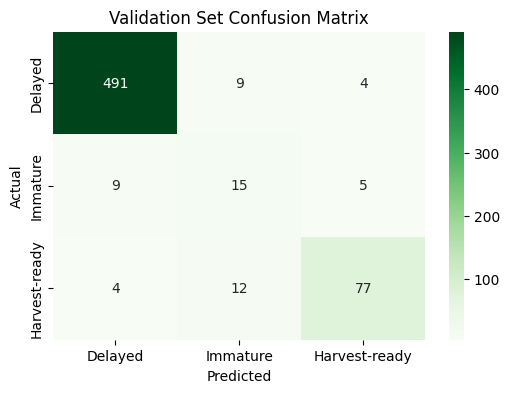

In [ ]:
# VALIDATION SET CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Delayed', 'Immature', 'Harvest-ready']
cm_val = confusion_matrix(y_val, y_val_pred, labels=labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.title("Validation Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

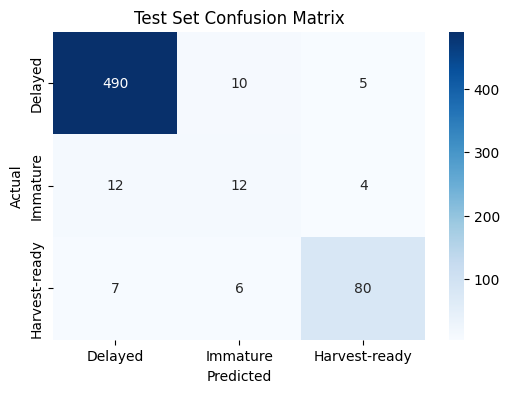

In [ ]:
# TEST SET CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['Delayed', 'Immature', 'Harvest-ready']

cm_test = confusion_matrix(y_test, y_test_pred, labels=labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title("Test Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

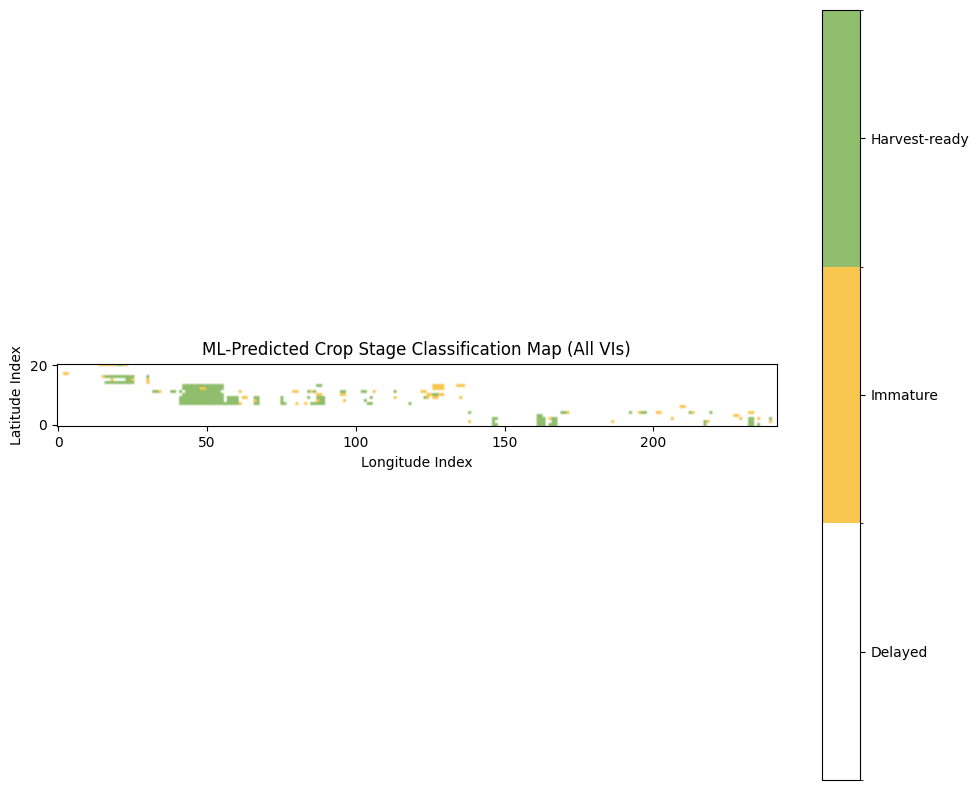

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.tree import DecisionTreeClassifier

# 1. Load the standardized dataset (with all VIs)
df = pd.read_csv("Crop_Harvest_Prediction_Model_all VIs_STANDARDIZED.csv")

# 2. Create NDVI-based label for training the classifier
def label_crop_stage(ndvi):
    if ndvi > 0.6:
        return 'Harvest-ready'
    elif ndvi > 0.3:
        return 'Immature'
    else:
        return 'Delayed'

df['label'] = df['ndvi'].apply(label_crop_stage)

# 3. Prepare training features and target label
features = ['ndvi', 'savi', 'ndmi', 'evi', 'revi']
X = df[features]
y = df['label']

# 4. Train Decision Tree classifier
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

# 5. Predict crop stage using all VIs
df['predicted_label'] = model.predict(X)

# 6. Map lat/lon to grid positions
latitudes = df['latitude'].round(5)
longitudes = df['longitude'].round(5)
lat_unique = np.sort(latitudes.unique())
lon_unique = np.sort(longitudes.unique())

lat_to_idx = {lat: i for i, lat in enumerate(lat_unique)}
lon_to_idx = {lon: i for i, lon in enumerate(lon_unique)}

# 7. Define label-color mapping
label_order = ['Delayed', 'Immature', 'Harvest-ready']
label_to_int = {label: idx for idx, label in enumerate(label_order)}
colors = ['#ffffff', '#f9c74f', '#90be6d']  # red, yellow, green

# 8. Initialize the classification map grid
grid = np.full((len(lat_unique), len(lon_unique)), -1)

for i in range(len(df)):
    row = lat_to_idx[latitudes.iloc[i]]
    col = lon_to_idx[longitudes.iloc[i]]
    label = df['predicted_label'].iloc[i]
    grid[row, col] = label_to_int[label]

# 9. Create and plot heatmap
cmap = mcolors.ListedColormap(colors)
bounds = np.arange(len(label_order) + 1) - 0.5
norm = mcolors.BoundaryNorm(bounds, cmap.N)

plt.figure(figsize=(10, 8))
im = plt.imshow(grid, cmap=cmap, norm=norm, origin='lower')
cbar = plt.colorbar(im, ticks=range(len(label_order)))
cbar.ax.set_yticklabels(label_order)
plt.title("ML-Predicted Crop Stage Classification Map (All VIs)")
plt.xlabel("Longitude Index")
plt.ylabel("Latitude Index")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Load the standardized dataset
df = pd.read_csv("Crop_Harvest_Prediction_Model_all VIs_STANDARDIZED.csv")

# Ensure lat/lon are numeric and handle potential errors
df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')

# Drop rows where lat/lon could not be converted
df.dropna(subset=['latitude', 'longitude'], inplace=True)

# Rounding to handle floating-point precision for unique values
latitudes = df['latitude'].round(5)
longitudes = df['longitude'].round(5)

# Get unique sorted latitudes and longitudes
lat_unique = np.sort(latitudes.unique())
lon_unique = np.sort(longitudes.unique())

# Calculate grid dimensions
num_lat = len(lat_unique)
num_lon = len(lon_unique)

print(f"DEBUG: Number of unique latitude values (rows in grid): {num_lat}")
print(f"DEBUG: Number of unique longitude values (columns in grid): {num_lon}")

if num_lat > 0:
    print(f"DEBUG: Calculated aspect ratio of the data grid (width/height): {num_lon / num_lat:.2f}")
else:
    print("DEBUG: No unique latitude values found after processing.")

DEBUG: Number of unique latitude values (rows in grid): 21
DEBUG: Number of unique longitude values (columns in grid): 242
DEBUG: Calculated aspect ratio of the data grid (width/height): 11.52
